# M1 - Data cleaning: King County house sales

**Role:** M1 (data cleaning)
**Project:** decide whether the asking price of a house is fair, in 4 classes, with one Decision Tree and a small Flask site.
**Dataset:** Kaggle, *House Sales in King County, USA* (21,613 rows, 21 columns).

This notebook only does the cleaning. The price category (the label) is created later by M2, and I don't scale, encode or train anything here. The price stays in the data on purpose, because the model uses it as an input.

When you run everything you get:
- `data/clean/house_clean.csv`, the cleaned data for M2 and M3
- `sample_data/sample_houses.csv`, 30 rows to test the web app
- `reports/M1_data_cleaning_report.xlsx`, a table of every change I made

I don't remove expensive or very large houses here. They can be real luxury homes, and whether to treat them as outliers should be decided with M2 and M3 once we see how the model behaves.

`random_state = 42` is used everywhere so the sample is always the same.

## Step 1 - Imports and settings

Libraries first, plus a few display options so wide tables are not cut off. I also create the empty `cleaning_log` list here. Every later step adds one line to it, and at the end it becomes the Excel report.

In [1]:
#  Standard libraries 
import os
import warnings

#  Data manipulation 
import numpy as np
import pandas as pd

#  Visualisation 
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

#  Reproducibility 
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

#  Display settings 
pd.set_option('display.max_columns', 30)        # show all columns in head()
pd.set_option('display.float_format', '{:,.2f}'.format)  # readable floats
pd.set_option('display.max_rows', 60)
warnings.filterwarnings('ignore')               # suppress matplotlib warnings

#  Plot style 
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 100

#  Cleaning log (accumulated throughout the notebook) 
cleaning_log = []

print('All imports OK. random_state =', RANDOM_STATE)

All imports OK. random_state = 42


## Step 2 - Load the raw data

Load the CSV and take a first look: shape, first rows, column types. I'm not changing anything yet, just checking that the file loaded properly.

I expect about 21,600 rows and 21 columns. If the shape is far from that, the path is probably wrong (it is relative to the `notebooks/` folder, hence the `../`).

In [2]:
# Path is relative to the notebooks/ folder, so we go up one level
RAW_PATH = '../data/raw/usa_house_data.csv'

df = pd.read_csv(RAW_PATH)

print(f'Loaded: {RAW_PATH}')
print(f'Shape  : {df.shape[0]:,} rows x {df.shape[1]} columns')

Loaded: ../data/raw/usa_house_data.csv
Shape  : 21,613 rows x 21 columns


In [3]:
# First 5 rows — just to see what the data looks like
print('=== head(5) ===')
display(df.head(5))

=== head(5) ===


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.00",3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650
1,6414100192,20141209T000000,"538,000.00",3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639
2,5631500400,20150225T000000,"180,000.00",2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,98028,47.74,-122.23,2720,8062
3,2487200875,20141209T000000,"604,000.00",4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000
4,1954400510,20150218T000000,"510,000.00",3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503


In [4]:
# Column names and data types
print('=== Columns & dtypes ===')
print(df.dtypes.to_string())

=== Columns & dtypes ===
id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64


In [5]:
# Info gives non-null counts and memory use
print('=== df.info() ===')
df.info()

=== df.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18 

## Step 3 - Missing values

Count the missing values in each column. Empty cells can make a model crash or give strange results, so each column with gaps would need a decision.

The rule of thumb I follow:
- more than 50% missing: drop the column
- less than 5% missing: drop those rows
- in between: keep the NaN and let the imputer in M3's pipeline fill it

In this dataset nothing is missing, so the code only reports it and there is nothing to apply. I kept the rule and the threshold lines on the chart in case the data changes.

In [6]:
# Count and percentage of missing values per column
rows_before_missing = len(df)

missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_%':    (df.isnull().mean() * 100).round(2)
}).sort_values('missing_%', ascending=False)

print('=== Missing values per column ===')
display(missing)

=== Missing values per column ===


,missing_count,missing_%
id,0,0.00
date,0,0.00
price,0,0.00
bedrooms,0,0.00
bathrooms,0,0.00
sqft_living,0,0.00
sqft_lot,0,0.00
floors,0,0.00
waterfront,0,0.00
view,0,0.00


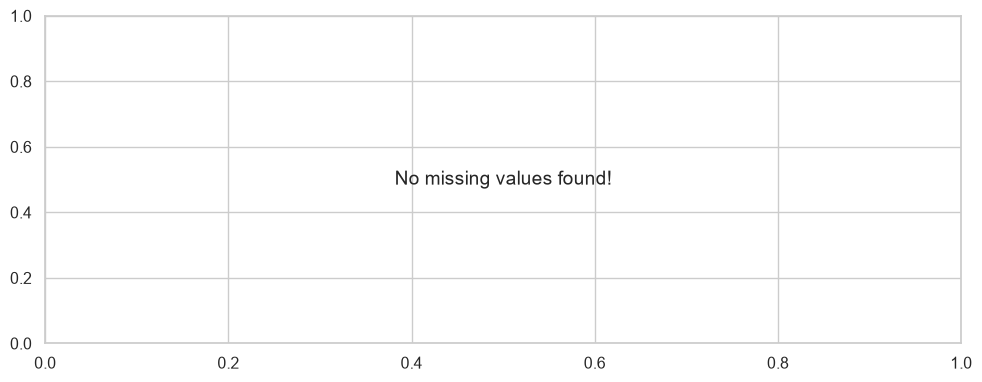


Total missing cells: 0
No missing values found. No action needed.


In [7]:
# Bar plot — orange dashed line = 5% threshold, red = 50% threshold
fig, ax = plt.subplots(figsize=(10, 4))
cols_with_missing = missing[missing['missing_%'] > 0]

if cols_with_missing.empty:
    ax.text(0.5, 0.5, 'No missing values found!',
            ha='center', va='center', fontsize=14, transform=ax.transAxes)
else:
    cols_with_missing['missing_%'].plot(kind='bar', ax=ax, color='steelblue')
    ax.axhline(5,  color='orange', linestyle='--', label='5% — drop rows')
    ax.axhline(50, color='red',    linestyle='--', label='50% — drop column')
    ax.set_ylabel('Missing %')
    ax.set_title('Missing Values by Column')
    ax.legend()

plt.tight_layout()
plt.show()

# Decision
total_missing = df.isnull().sum().sum()
print(f'\nTotal missing cells: {total_missing}')
if total_missing == 0:
    print('No missing values found. No action needed.')
    cleaning_log.append({
        'step': '3 - Missing values',
        'action': 'No missing values found — no action taken',
        'rows_before': rows_before_missing,
        'rows_after': len(df),
        'details': 'All 21 columns have 0 missing values'
    })
else:
    print('See decision logic in markdown cell above.')

## Step 4 - Distributions before cleaning

I plot every variable before changing anything. It shows what the raw data looks like and gives me something to compare with after the cleaning.

- Numeric columns get a histogram and a boxplot side by side. `price`, `sqft_lot` and `sqft_lot15` have a very long tail, so they use a log x-axis, otherwise everything is squeezed on the left.
- Columns with few distinct values (bedrooms, floors, waterfront, grade...) get a bar chart of counts.
- `zipcode` has too many values to show, so only the 20 most frequent are plotted and the title gives the total number of distinct codes.

In [8]:
# Define which columns belong to which group
NUMERIC_COLS = [
    'price', 'sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement',
    'sqft_living15', 'sqft_lot15', 'yr_built', 'yr_renovated', 'lat', 'long'
]

DISCRETE_COLS = [
    'bedrooms', 'bathrooms', 'floors',
    'waterfront', 'view', 'condition', 'grade', 'zipcode'
]

# Columns with very skewed distributions that are easier to read on a log scale
LOG_SCALE_COLS = {'price', 'sqft_lot', 'sqft_lot15'}

print('Numeric columns  :', NUMERIC_COLS)
print('Discrete columns :', DISCRETE_COLS)

Numeric columns  : ['price', 'sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement', 'sqft_living15', 'sqft_lot15', 'yr_built', 'yr_renovated', 'lat', 'long']
Discrete columns : ['bedrooms', 'bathrooms', 'floors', 'waterfront', 'view', 'condition', 'grade', 'zipcode']


In [9]:
# Helper function: draw histogram + boxplot side by side for one numeric column
def plot_numeric_distribution(series, col_name, use_log=False, ax_hist=None, ax_box=None):
    """Plot histogram and horizontal boxplot for `series`."""
    data = series.dropna()
    # histogram
    ax_hist.hist(data, bins=50, color='steelblue', edgecolor='none', alpha=0.85)
    if use_log:
        ax_hist.set_xscale('log')
        ax_hist.set_title(f'{col_name}\n(log x-axis)', fontsize=9)
    else:
        ax_hist.set_title(col_name, fontsize=9)
    ax_hist.set_ylabel('Count', fontsize=8)
    ax_hist.tick_params(labelsize=7)
    # boxplot
    ax_box.boxplot(data, vert=False, patch_artist=True,
                   boxprops=dict(facecolor='lightsteelblue'),
                   medianprops=dict(color='red', linewidth=1.5),
                   flierprops=dict(marker='.', markersize=2, alpha=0.4))
    if use_log:
        ax_box.set_xscale('log')
    ax_box.set_yticks([])
    ax_box.tick_params(labelsize=7)

print('Helper function defined.')

Helper function defined.


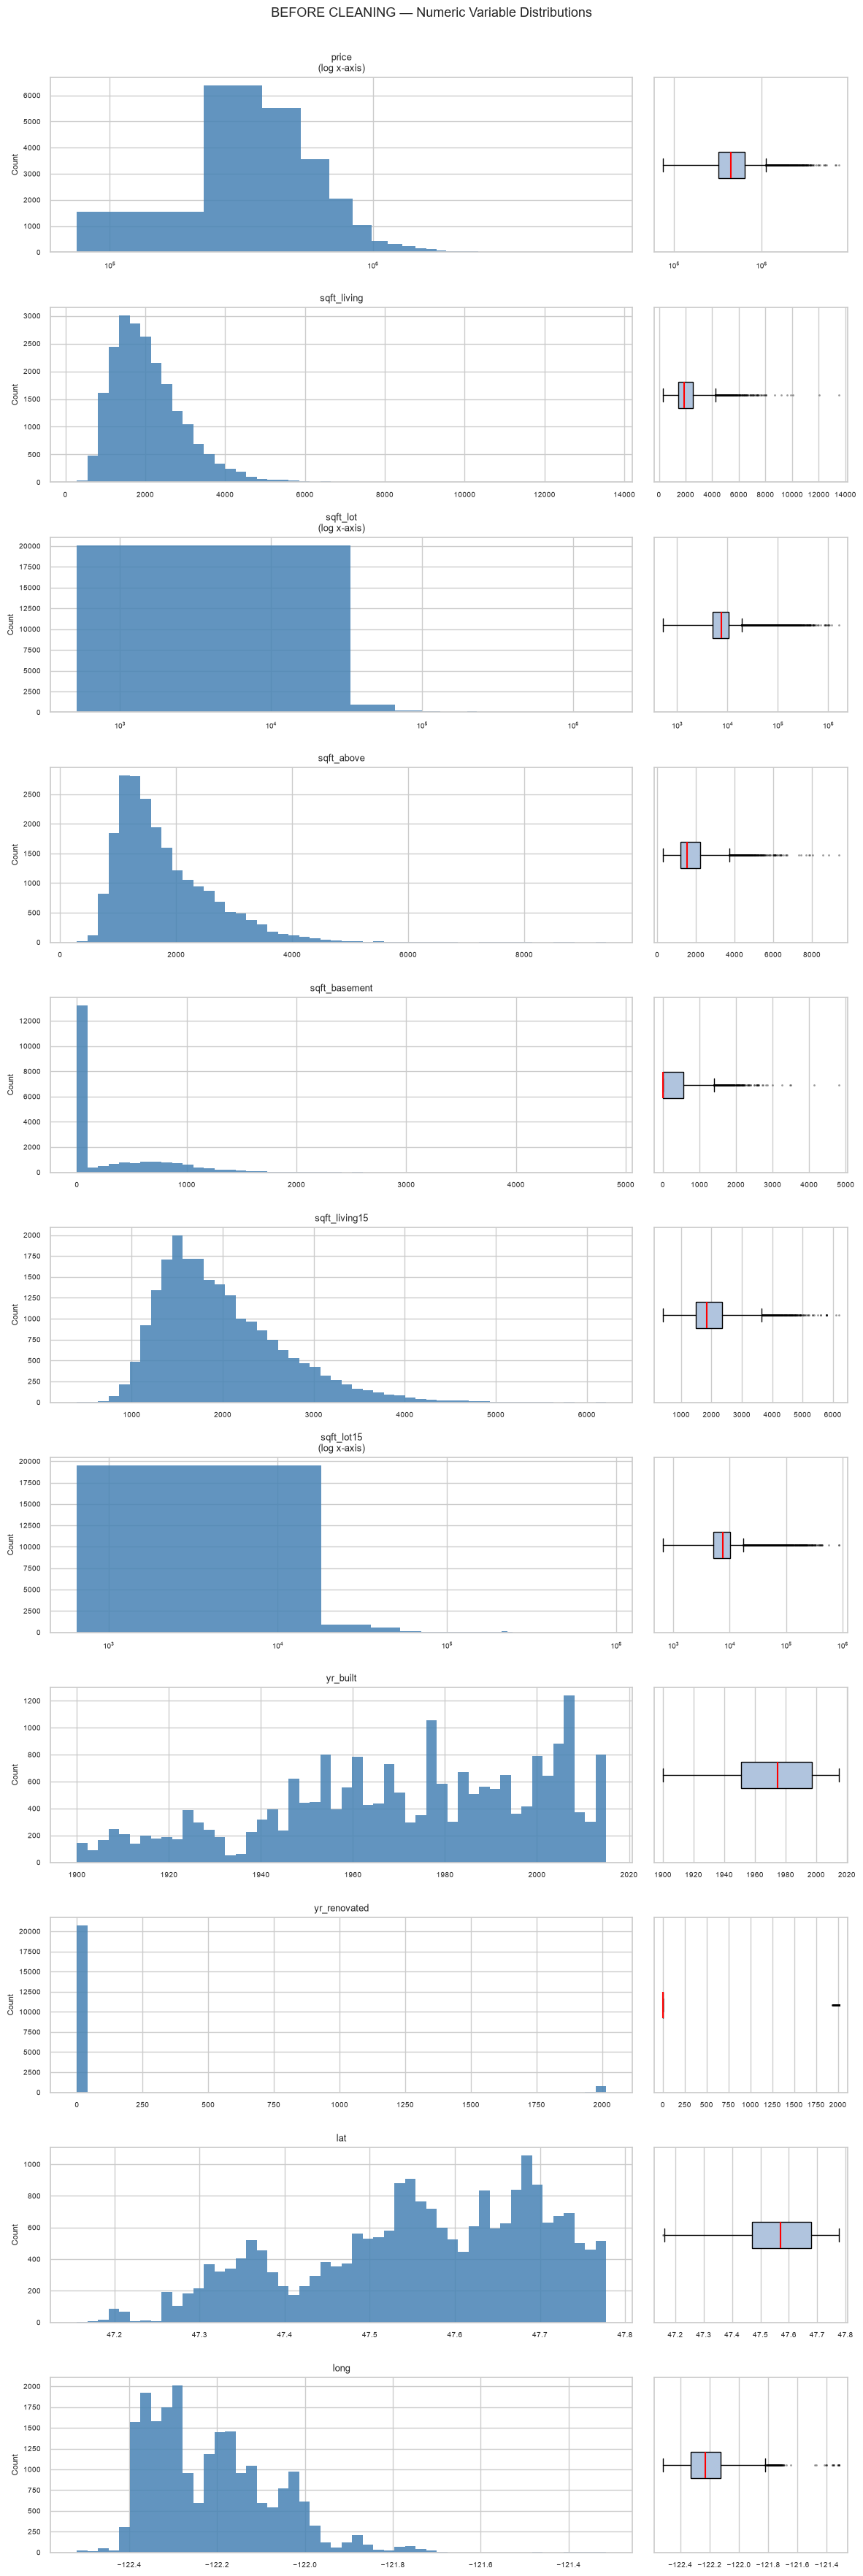

Numeric distributions plotted.


In [10]:
# Plot all numeric columns (histogram on the left, boxplot on the right)
n_cols_plot = len(NUMERIC_COLS)
fig, axes = plt.subplots(nrows=n_cols_plot, ncols=2,
                         figsize=(12, 3.2 * n_cols_plot),
                         gridspec_kw={'width_ratios': [3, 1]})

fig.suptitle('BEFORE CLEANING — Numeric Variable Distributions', fontsize=13, y=1.002)

for i, col in enumerate(NUMERIC_COLS):
    use_log = col in LOG_SCALE_COLS
    plot_numeric_distribution(df[col], col, use_log=use_log,
                               ax_hist=axes[i, 0], ax_box=axes[i, 1])

plt.tight_layout()
plt.show()
print('Numeric distributions plotted.')

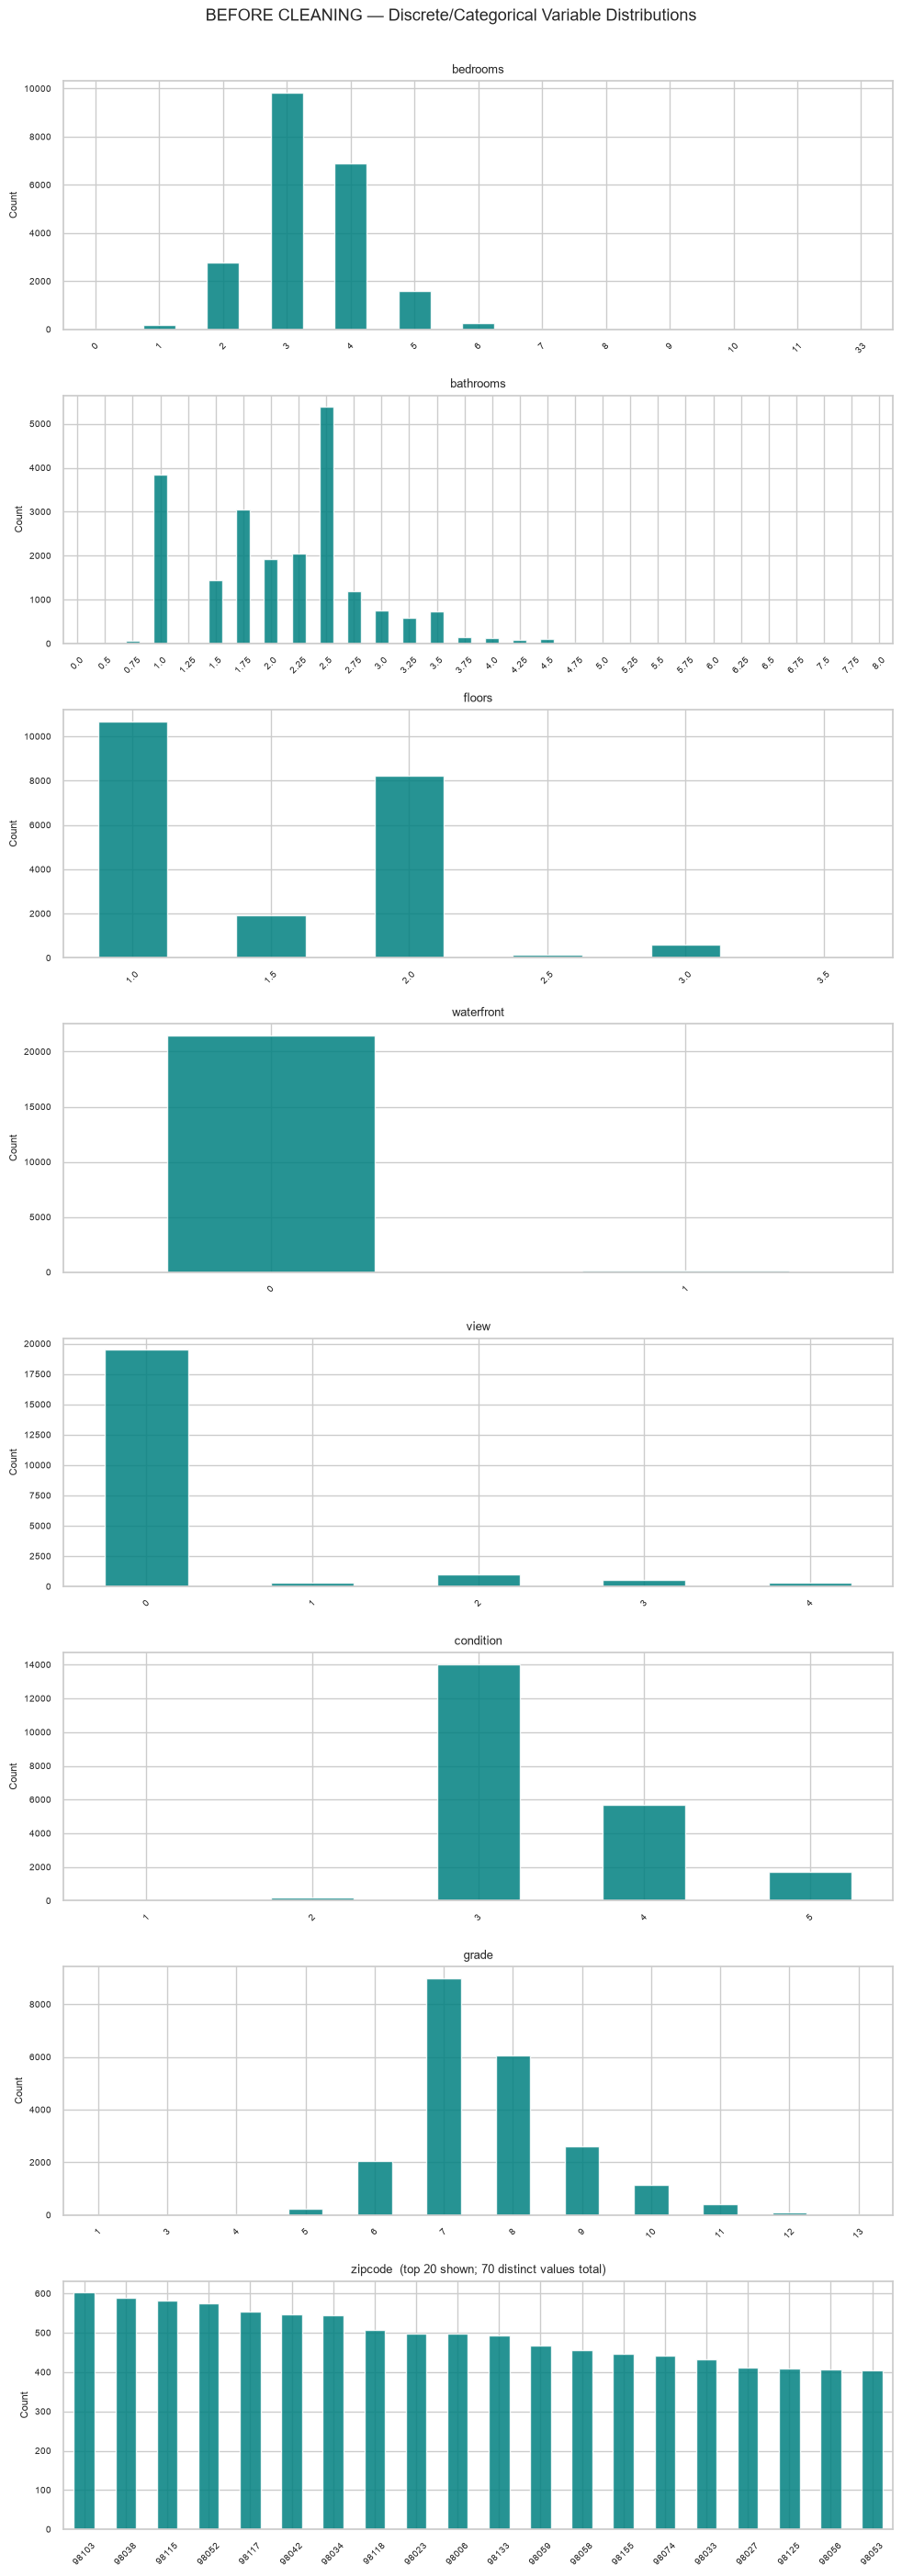

Discrete distributions plotted.


In [11]:
# Plot all discrete/categorical columns (bar chart of value counts)
n_disc = len(DISCRETE_COLS)
fig, axes = plt.subplots(nrows=n_disc, ncols=1,
                         figsize=(10, 3.5 * n_disc))

fig.suptitle('BEFORE CLEANING — Discrete/Categorical Variable Distributions',
             fontsize=13, y=1.002)

for i, col in enumerate(DISCRETE_COLS):
    ax = axes[i]
    vc = df[col].value_counts().sort_index()

    if col == 'zipcode':
        # Too many zipcodes to show all — display top 20 only
        vc_show = df[col].value_counts().head(20)
        vc_show.plot(kind='bar', ax=ax, color='teal', alpha=0.85)
        n_distinct = df[col].nunique()
        ax.set_title(f'{col}  (top 20 shown; {n_distinct} distinct values total)', fontsize=9)
    else:
        vc.plot(kind='bar', ax=ax, color='teal', alpha=0.85)
        ax.set_title(f'{col}', fontsize=9)

    ax.set_xlabel('')
    ax.set_ylabel('Count', fontsize=8)
    ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.show()
print('Discrete distributions plotted.')

### What I notice in the raw plots

| Variable | Observation |
|---|---|
| `price` | Strong right skew, a few houses cost millions. On a log scale it looks much more regular. Goes from about $75k to $7.7M. |
| `sqft_lot` | Even more skewed than price: most lots are small, a few are huge. |
| `sqft_lot15` | Same shape as `sqft_lot`, which makes sense (same measure, for the neighbours). |
| `yr_renovated` | About 96% of the values are 0, meaning "never renovated". As a year it would mislead the model, so a yes/no flag is better. |
| `bedrooms` | One bar sits at 33 bedrooms, obviously an error for a ~1,600 sqft house. |
| `bathrooms` | A few houses have 0 bathrooms. Strange, but I need to look at them before deciding. |
| `waterfront` | Less than 1% of the houses are waterfront. Very unbalanced, but that is how the market is. |
| `view` | Most houses have view = 0. |
| `zipcode` | 70 different codes, and some areas have far more sales than others. |
| `lat`, `long` | Everything is inside the King County area, no coordinate looks wrong. |

## Step 5 - Fix data types and check ranges

Two columns have the wrong type:
- `date` is a string like `20141013T000000`, so I convert it to a real date.
- `zipcode` is an integer, but nobody does arithmetic on a ZIP code. It is a label, so it becomes a string.

Then I check that `waterfront`, `view`, `condition` and `grade` stay inside the ranges given in the dataset description. A value outside would mean a corrupted row.

In [12]:
# 5a: Convert date to datetime
# The format is '20141013T000000' — year-month-day then time
rows_before = len(df)

df['date'] = pd.to_datetime(df['date'], format='%Y%m%dT%H%M%S', errors='coerce')

failed_dates = df['date'].isnull().sum()
print(f'date  : converted to datetime64.  Failed conversions (NaT): {failed_dates}')
print(f'Sample values: {df["date"].head(3).tolist()}')

cleaning_log.append({
    'step': '5a - Fix types',
    'action': 'Convert date to datetime64',
    'rows_before': rows_before,
    'rows_after': len(df),
    'details': f'{failed_dates} values could not be parsed (NaT)'
})

date  : converted to datetime64.  Failed conversions (NaT): 0
Sample values: [Timestamp('2014-10-13 00:00:00'), Timestamp('2014-12-09 00:00:00'), Timestamp('2015-02-25 00:00:00')]


In [13]:
# 5b: Convert zipcode from integer to string
# Zipcode is a geographic label — treating it as a number makes no sense
df['zipcode'] = df['zipcode'].astype(str).str.strip()

print(f'zipcode: converted to string.  dtype = {df["zipcode"].dtype}')
print(f'Sample values: {df["zipcode"].unique()[:5]}')

cleaning_log.append({
    'step': '5b - Fix types',
    'action': 'Convert zipcode from int64 to string',
    'rows_before': len(df),
    'rows_after': len(df),
    'details': 'Zipcode is a label, not a number. Arithmetic on it is meaningless.'
})

zipcode: converted to string.  dtype = str
Sample values: <StringArray>
['98178', '98125', '98028', '98136', '98074']
Length: 5, dtype: str


In [14]:
# 5c: Check that categorical columns are within their allowed ranges
# Ranges come from the Kaggle dataset description
range_checks = {
    'waterfront': (0, 1),
    'view':       (0, 4),
    'condition':  (1, 5),
    'grade':      (1, 13),
}

for col, (lo, hi) in range_checks.items():
    out_of_range = df[(df[col] < lo) | (df[col] > hi)]
    print(f'{col:12s}  allowed [{lo}, {hi}]  ->  out-of-range rows: {len(out_of_range)}')
    if not out_of_range.empty:
        display(out_of_range[[col]].value_counts())

print('\nRange checks complete.')

waterfront    allowed [0, 1]  ->  out-of-range rows: 0
view          allowed [0, 4]  ->  out-of-range rows: 0
condition     allowed [1, 5]  ->  out-of-range rows: 0
grade         allowed [1, 13]  ->  out-of-range rows: 0

Range checks complete.


## Step 6 - Duplicates

Two kinds of duplicates to look for:

1. Rows that are identical in every column. Easy, just drop them.
2. Houses sold more than once. The same `id` shows up with different dates and prices. I want one row per house, so I keep the most recent sale, since it is the closest to the current value of the house.

This has to be done now, before `id` is dropped in Step 9, because I need `id` to find the repeated houses.

In [15]:
# 6a: Check for fully identical rows
rows_before_6a = len(df)
n_full_dups = df.duplicated().sum()

print(f'Fully duplicate rows found: {n_full_dups}')

if n_full_dups > 0:
    df.drop_duplicates(inplace=True)
    print(f'  Removed {n_full_dups} fully duplicate rows.')
else:
    print('  No action needed.')

print(f'Shape after: {df.shape}')

cleaning_log.append({
    'step': '6a - Duplicates',
    'action': 'Drop fully duplicate rows',
    'rows_before': rows_before_6a,
    'rows_after': len(df),
    'details': f'{n_full_dups} fully duplicate rows removed'
})

Fully duplicate rows found: 0
  No action needed.
Shape after: (21613, 21)


In [16]:
# 6b: Houses sold more than once — same id, different date
rows_before_6b = len(df)
n_dup_ids = df['id'].duplicated().sum()

print(f'Duplicate id entries (houses with more than one sale record): {n_dup_ids}')

# Show a few examples so it is clear what we are dealing with
dup_id_examples = df[df['id'].duplicated(keep=False)].sort_values(['id', 'date'])
print(f'\nSample of re-sold houses (showing id, date, price):')
display(dup_id_examples[['id', 'date', 'price']].head(10))

Duplicate id entries (houses with more than one sale record): 177

Sample of re-sold houses (showing id, date, price):


,id,date,price
2496,1000102,2014-09-16,"280,000.00"
2497,1000102,2015-04-22,"300,000.00"
16814,7200179,2014-10-16,"150,000.00"
16815,7200179,2015-04-24,"175,000.00"
11433,109200390,2014-08-20,"245,000.00"
11434,109200390,2014-10-20,"250,000.00"
12417,123039336,2014-06-11,"148,000.00"
12418,123039336,2014-12-08,"244,900.00"
7792,251300110,2014-07-31,"225,000.00"
7793,251300110,2015-01-14,"358,000.00"


In [17]:
# Keep only the most recent sale for each house id.
# Sort by date newest first, then keep the first row for each id.
df.sort_values('date', ascending=False, inplace=True)
df.drop_duplicates(subset='id', keep='first', inplace=True)
df.reset_index(drop=True, inplace=True)

rows_removed_6b = rows_before_6b - len(df)
print(f'Removed {rows_removed_6b} older re-sale rows (kept most recent sale per house).')
print(f'Shape after: {df.shape}')

cleaning_log.append({
    'step': '6b - Duplicate IDs',
    'action': 'Keep only most recent sale per house id',
    'rows_before': rows_before_6b,
    'rows_after': len(df),
    'details': f'{rows_removed_6b} older re-sale rows removed'
})

Removed 177 older re-sale rows (kept most recent sale per house).
Shape after: (21436, 21)


## Step 7 - Impossible and suspicious values

Some rows are wrong just by common sense. For each check I print the affected rows first and only then decide, so the choice can be followed.

My rule: if the value is physically impossible, the row goes. If it is unusual but could be real, it stays, and it becomes a question of outliers for M2 and M3.

In [18]:
# 7a: Remove rows where price <= 0 or sqft_living <= 0
# A house with zero or negative price, or zero square footage, cannot exist.
rows_before_7a = len(df)

mask_bad_price  = df['price'] <= 0
mask_bad_sqft   = df['sqft_living'] <= 0
mask_7a         = mask_bad_price | mask_bad_sqft

print(f'price <= 0      : {mask_bad_price.sum()} rows')
print(f'sqft_living <= 0: {mask_bad_sqft.sum()} rows')
print(f'Total to remove : {mask_7a.sum()} rows')

if mask_7a.any():
    display(df[mask_7a][['id', 'price', 'sqft_living']])

df = df[~mask_7a].reset_index(drop=True)
print(f'\nShape after: {df.shape}')

cleaning_log.append({
    'step': '7a - Impossible values',
    'action': 'Remove rows with price <= 0 or sqft_living <= 0',
    'rows_before': rows_before_7a,
    'rows_after': len(df),
    'details': f'{mask_7a.sum()} rows removed'
})

price <= 0      : 0 rows
sqft_living <= 0: 0 rows
Total to remove : 0 rows

Shape after: (21436, 21)


In [19]:
# 7b: Remove rows where bedrooms == 0 AND bathrooms == 0
# A house with no bedrooms and no bathrooms is not a liveable property.
rows_before_7b = len(df)

mask_7b = (df['bedrooms'] == 0) & (df['bathrooms'] == 0)
print(f'Rows with bedrooms=0 AND bathrooms=0: {mask_7b.sum()}')

if mask_7b.any():
    display(df[mask_7b][['id', 'bedrooms', 'bathrooms', 'sqft_living', 'price']])

df = df[~mask_7b].reset_index(drop=True)
print(f'Shape after: {df.shape}')

cleaning_log.append({
    'step': '7b - Impossible values',
    'action': 'Remove rows with bedrooms=0 AND bathrooms=0',
    'rows_before': rows_before_7b,
    'rows_after': len(df),
    'details': f'{mask_7b.sum()} uninhabitable rows removed'
})

Rows with bedrooms=0 AND bathrooms=0: 7


,id,bedrooms,bathrooms,sqft_living,price
729,3374500520,0,0.00,2460,"355,000.00"
2058,9543000205,0,0.00,844,"139,950.00"
5812,3918400017,0,0.00,1470,"380,000.00"
7203,7849202190,0,0.00,1470,"235,000.00"
11891,3980300371,0,0.00,290,"142,000.00"
18007,2954400190,0,0.00,4810,"1,295,650.00"
18873,6306400140,0,0.00,3064,"1,095,000.00"


Shape after: (21429, 21)


In [20]:
# 7c: Rows with bedrooms == 0 but bathrooms > 0 — let's look at these
# These survived the previous step because they have at least one bathroom.
mask_0bed = df['bedrooms'] == 0
print(f'Rows with bedrooms == 0 (but bathrooms > 0): {mask_0bed.sum()}')
if mask_0bed.any():
    display(df[mask_0bed][['id', 'bedrooms', 'bathrooms', 'sqft_living', 'price']])
    print('\nDecision: KEEP — studio apartments with 0 bedrooms are a real property type.')

Rows with bedrooms == 0 (but bathrooms > 0): 6


,id,bedrooms,bathrooms,sqft_living,price
5350,7849202299,0,2.50,1490,"320,000.00"
8995,2569500210,0,2.50,2290,"339,950.00"
10019,1222029077,0,0.75,384,"265,000.00"
11558,6896300380,0,1.00,390,"228,000.00"
11933,2310060040,0,2.50,1810,"240,000.00"
15094,1453602309,0,1.50,1430,"288,000.00"



Decision: KEEP — studio apartments with 0 bedrooms are a real property type.


In [21]:
# 7d: Bedrooms >= 10 — are these real or typos?
# First just look at them.
rows_before_7d = len(df)

mask_7d = df['bedrooms'] >= 10
print(f'Rows with bedrooms >= 10: {mask_7d.sum()}')
display(df[mask_7d][['id', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'price']])

Rows with bedrooms >= 10: 5


,id,bedrooms,bathrooms,sqft_living,sqft_lot,price
7081,8812401450,10,3.00,2920,3745,"660,000.00"
10028,5566100170,10,2.00,3610,11914,"650,000.00"
14012,1773100755,11,3.00,3000,4960,"520,000.00"
14507,627300145,10,5.25,4590,10920,"1,148,000.00"
17956,2402100895,33,1.75,1620,6000,"640,000.00"


In [22]:
# Decision on the large-bedroom rows:
# The 33-bedroom house has only 1,620 sqft — that is about 49 sqft per bedroom,
# which is physically impossible. It is clearly a data entry error (probably meant '3').
# I remove only rows where sqft_living < 200 * bedrooms, meaning less than 200 sqft
# per bedroom on average. A 10-bedroom house with 2,920 sqft (~290 sqft each)
# could be a large group home, so those are kept.

mask_typo = (df['bedrooms'] >= 10) & (df['sqft_living'] < 200 * df['bedrooms'])
print(f'Rows flagged as bedroom count typos (less than 200 sqft per bedroom): {mask_typo.sum()}')
display(df[mask_typo][['id', 'bedrooms', 'bathrooms', 'sqft_living', 'price']])

df = df[~mask_typo].reset_index(drop=True)
rows_removed_7d = rows_before_7d - len(df)
print(f'\nRemoved {rows_removed_7d} rows (bedroom count typos).')
print(f'Shape after: {df.shape}')

cleaning_log.append({
    'step': '7d - Suspicious bedrooms',
    'action': 'Remove rows where bedrooms >= 10 AND sqft_living < 200 * bedrooms (typo)',
    'rows_before': rows_before_7d,
    'rows_after': len(df),
    'details': f'{rows_removed_7d} rows removed (e.g., 33-bedroom/1620 sqft house)'
})

Rows flagged as bedroom count typos (less than 200 sqft per bedroom): 1


,id,bedrooms,bathrooms,sqft_living,price
17956,2402100895,33,1.75,1620,"640,000.00"



Removed 1 rows (bedroom count typos).
Shape after: (21428, 21)


In [23]:
# 7e: Bathrooms == 0 — should these stay?
mask_0bath = df['bathrooms'] == 0
print(f'Rows with bathrooms == 0: {mask_0bath.sum()}')

if mask_0bath.any():
    display(df[mask_0bath][['id', 'bedrooms', 'bathrooms', 'sqft_living', 'price']].head(10))
    print('\nDecision: KEEP — these have at least 1 bedroom, so they are liveable.')
    print('  The 0 bathrooms probably means the listing was incomplete, not that the house has none.')

Rows with bathrooms == 0: 3


,id,bedrooms,bathrooms,sqft_living,price
5416,3421079032,1,0.00,670,"75,000.00"
9695,5702500050,1,0.00,600,"280,000.00"
12386,203100435,1,0.00,690,"484,000.00"



Decision: KEEP — these have at least 1 bedroom, so they are liveable.
  The 0 bathrooms probably means the listing was incomplete, not that the house has none.


In [24]:
# 7f: Check year logic — yr_built should not be after the sale year,
# and yr_renovated should not be earlier than yr_built (when it is not 0).
df['sale_year'] = df['date'].dt.year

rows_before_7f = len(df)
mask_future_built = df['yr_built'] > df['sale_year']
print(f'Rows where yr_built > sale_year (built after it was sold): {mask_future_built.sum()}')

if mask_future_built.any():
    display(df[mask_future_built][['id', 'yr_built', 'sale_year', 'price']])
else:
    print('  No impossible yr_built values found.')

# Check renovation year makes sense
renovated_mask = df['yr_renovated'] != 0
mask_bad_renov  = renovated_mask & (df['yr_renovated'] < df['yr_built'])
print(f'\nRows where yr_renovated < yr_built (and renovated != 0): {mask_bad_renov.sum()}')

if mask_bad_renov.any():
    display(df[mask_bad_renov][['id', 'yr_built', 'yr_renovated', 'price']])

# Remove the temporary sale_year column — no longer needed
df.drop(columns=['sale_year'], inplace=True)

cleaning_log.append({
    'step': '7f - Date consistency',
    'action': 'Check yr_built vs sale year, yr_renovated vs yr_built',
    'rows_before': rows_before_7f,
    'rows_after': len(df),
    'details': (
        f'{mask_future_built.sum()} rows with yr_built > sale_year; '
        f'{mask_bad_renov.sum()} rows with yr_renovated < yr_built'
    )
})

Rows where yr_built > sale_year (built after it was sold): 12


,id,yr_built,sale_year,price
6980,9520900210,2015,2014,"614,285.00"
8513,5694500840,2015,2014,"559,000.00"
10013,3076500830,2015,2014,"385,195.00"
13548,9310300160,2015,2014,"357,000.00"
13718,2770601530,2015,2014,"500,000.00"
15295,9126100765,2015,2014,"455,000.00"
15346,6058600220,2015,2014,"230,000.00"
16963,1257201420,2015,2014,"595,000.00"
17888,1832100030,2015,2014,"597,326.00"
18018,1250200495,2015,2014,"455,000.00"



Rows where yr_renovated < yr_built (and renovated != 0): 0


In [26]:
# 7g: Check whether sqft_above + sqft_basement = sqft_living
# According to the dataset description this should always add up.
mismatch = (df['sqft_above'] + df['sqft_basement']) != df['sqft_living']
n_mismatch = mismatch.sum()
print(f'Rows where sqft_above + sqft_basement != sqft_living: {n_mismatch}')

if n_mismatch > 0:
    print('\nSample of mismatches:')
    display(df[mismatch][['sqft_living', 'sqft_above', 'sqft_basement']].head(10))
    diff = (df.loc[mismatch, 'sqft_above'] + df.loc[mismatch, 'sqft_basement'] - df.loc[mismatch, 'sqft_living'])
    print(f'\nDifference stats (above+basement minus living):')
    print(diff.describe())
    print('\nDecision: KEEP — the differences look like small rounding errors from the listing source.')
    print('  No rows removed.')

cleaning_log.append({
    'step': '7g - sqft consistency',
    'action': 'Report sqft_above + sqft_basement != sqft_living mismatches — no rows removed',
    'rows_before': len(df),
    'rows_after': len(df),
    'details': f'{n_mismatch} rows with sqft mismatch; kept as rounding artefacts'
})

Rows where sqft_above + sqft_basement != sqft_living: 0


In [27]:
# 7h: IQR outlier report — informational only, no rows removed here
# Using the standard 1.5 x IQR rule to count how many extreme values exist.
# These are listed so M2 and M3 can decide whether to treat them.
outlier_report = []

numeric_for_iqr = ['price', 'sqft_living', 'sqft_lot', 'bedrooms', 'bathrooms']

for col in numeric_for_iqr:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr     = q3 - q1
    lo, hi  = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out   = ((df[col] < lo) | (df[col] > hi)).sum()
    outlier_report.append({'column': col, 'Q1': q1, 'Q3': q3,
                           'IQR_lower': lo, 'IQR_upper': hi, 'outlier_count': n_out})

outlier_df = pd.DataFrame(outlier_report)
print('=== IQR Outlier Report (informational only — no rows removed) ===')
display(outlier_df)
print('\nAll these rows are KEPT. Outlier treatment will be decided together with M2 and M3.')

cleaning_log.append({
    'step': '7h - Outlier report',
    'action': 'IQR outlier report — no rows removed',
    'rows_before': len(df),
    'rows_after': len(df),
    'details': 'See outlier_df table above; decision deferred to M2/M3'
})

=== IQR Outlier Report (informational only — no rows removed) ===


,column,Q1,Q3,IQR_lower,IQR_upper,outlier_count
0,price,"324,897.00","645,000.00","-155,257.50","1,125,154.50",1142
1,sqft_living,"1,430.00","2,550.00",-250.00,"4,230.00",568
2,sqft_lot,"5,040.00","10,696.25","-3,444.38","19,180.62",2407
3,bedrooms,3.00,4.00,1.50,5.50,526
4,bathrooms,1.75,2.50,0.62,3.62,561



All these rows are KEPT. Outlier treatment will be decided together with M2 and M3.


## Step 8 - Turn `yr_renovated` into a yes/no column

About 96% of `yr_renovated` is 0, which here means "never renovated". Left as a year, the tree would read 0 as a real year, which is wrong. What matters is whether the house was renovated at all, not the exact year.

So I create `renovated` (1 if renovated, 0 if not) and drop `yr_renovated`.

In [28]:
rows_before_8 = len(df)

# How many houses have a renovation year recorded?
n_renovated = (df['yr_renovated'] != 0).sum()
print(f'Houses with yr_renovated != 0 (renovated at some point): {n_renovated}')
print(f'Houses with yr_renovated == 0 (never renovated)         : {(df["yr_renovated"] == 0).sum()}')

# Create binary flag
df['renovated'] = (df['yr_renovated'] != 0).astype(int)

# Drop the original year column
df.drop(columns=['yr_renovated'], inplace=True)

print(f'\nrenovated value_counts:')
print(df['renovated'].value_counts())
print(f'\nShape after: {df.shape}')

cleaning_log.append({
    'step': '8 - Feature fix',
    'action': 'Create renovated (0/1) from yr_renovated; drop yr_renovated',
    'rows_before': rows_before_8,
    'rows_after': len(df),
    'details': f'{n_renovated} houses flagged as renovated; yr_renovated column dropped'
})

Houses with yr_renovated != 0 (renovated at some point): 910
Houses with yr_renovated == 0 (never renovated)         : 20518

renovated value_counts:
renovated
0    20518
1      910
Name: count, dtype: int64

Shape after: (21428, 21)


## Step 9 - Drop the columns the web form cannot ask for

The website will ask the user to describe a house, so every column left in the data must be something a person can actually type in. These do not qualify:

| Column | Why it goes |
|---|---|
| `id` | Only a row identifier. It says nothing about the house and could let the tree memorise rows. |
| `date` | Date of a past sale. Someone checking a house today has no such date. |
| `lat`, `long` | Too precise, nobody knows their coordinates. `zipcode` already gives the location. |
| `sqft_living15`, `sqft_lot15` | Average size of the 15 nearest houses. A seller doesn't have that. |

In [29]:
rows_before_9 = len(df)
cols_before_9 = df.columns.tolist()

COLS_TO_DROP = ['id', 'date', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

df.drop(columns=COLS_TO_DROP, inplace=True)

print(f'Columns dropped : {COLS_TO_DROP}')
print(f'Columns before  : {len(cols_before_9)}')
print(f'Columns after   : {len(df.columns)}')
print(f'Remaining columns: {df.columns.tolist()}')
print(f'Shape after: {df.shape}')

cleaning_log.append({
    'step': '9 - Drop columns',
    'action': f'Drop {COLS_TO_DROP}',
    'rows_before': rows_before_9,
    'rows_after': len(df),
    'details': 'id=identifier; date=not entered by user; lat/long=too precise; sqft_*15=neighbours data'
})

Columns dropped : ['id', 'date', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
Columns before  : 21
Columns after   : 15
Remaining columns: ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'zipcode', 'renovated']
Shape after: (21428, 15)


## Step 10 - Distributions after cleaning

Same plots as Step 4, now on the cleaned data. Two things to check: the 33-bedroom bar should be gone, and the general shape of each variable should stay the same. If a distribution changed a lot, I removed something I shouldn't have.

In [2]:
# Define which columns are still in the data after cleaning
NUMERIC_COLS_CLEAN = [
    'price', 'sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement',
    'yr_built'
]

DISCRETE_COLS_CLEAN = [
    'bedrooms', 'bathrooms', 'floors',
    'waterfront', 'view', 'condition', 'grade', 'zipcode', 'renovated'
]

print('Numeric (after) :', NUMERIC_COLS_CLEAN)
print('Discrete (after) :', DISCRETE_COLS_CLEAN)

Numeric (after) : ['price', 'sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement', 'yr_built']
Discrete (after) : ['bedrooms', 'bathrooms', 'floors', 'waterfront', 'view', 'condition', 'grade', 'zipcode', 'renovated']


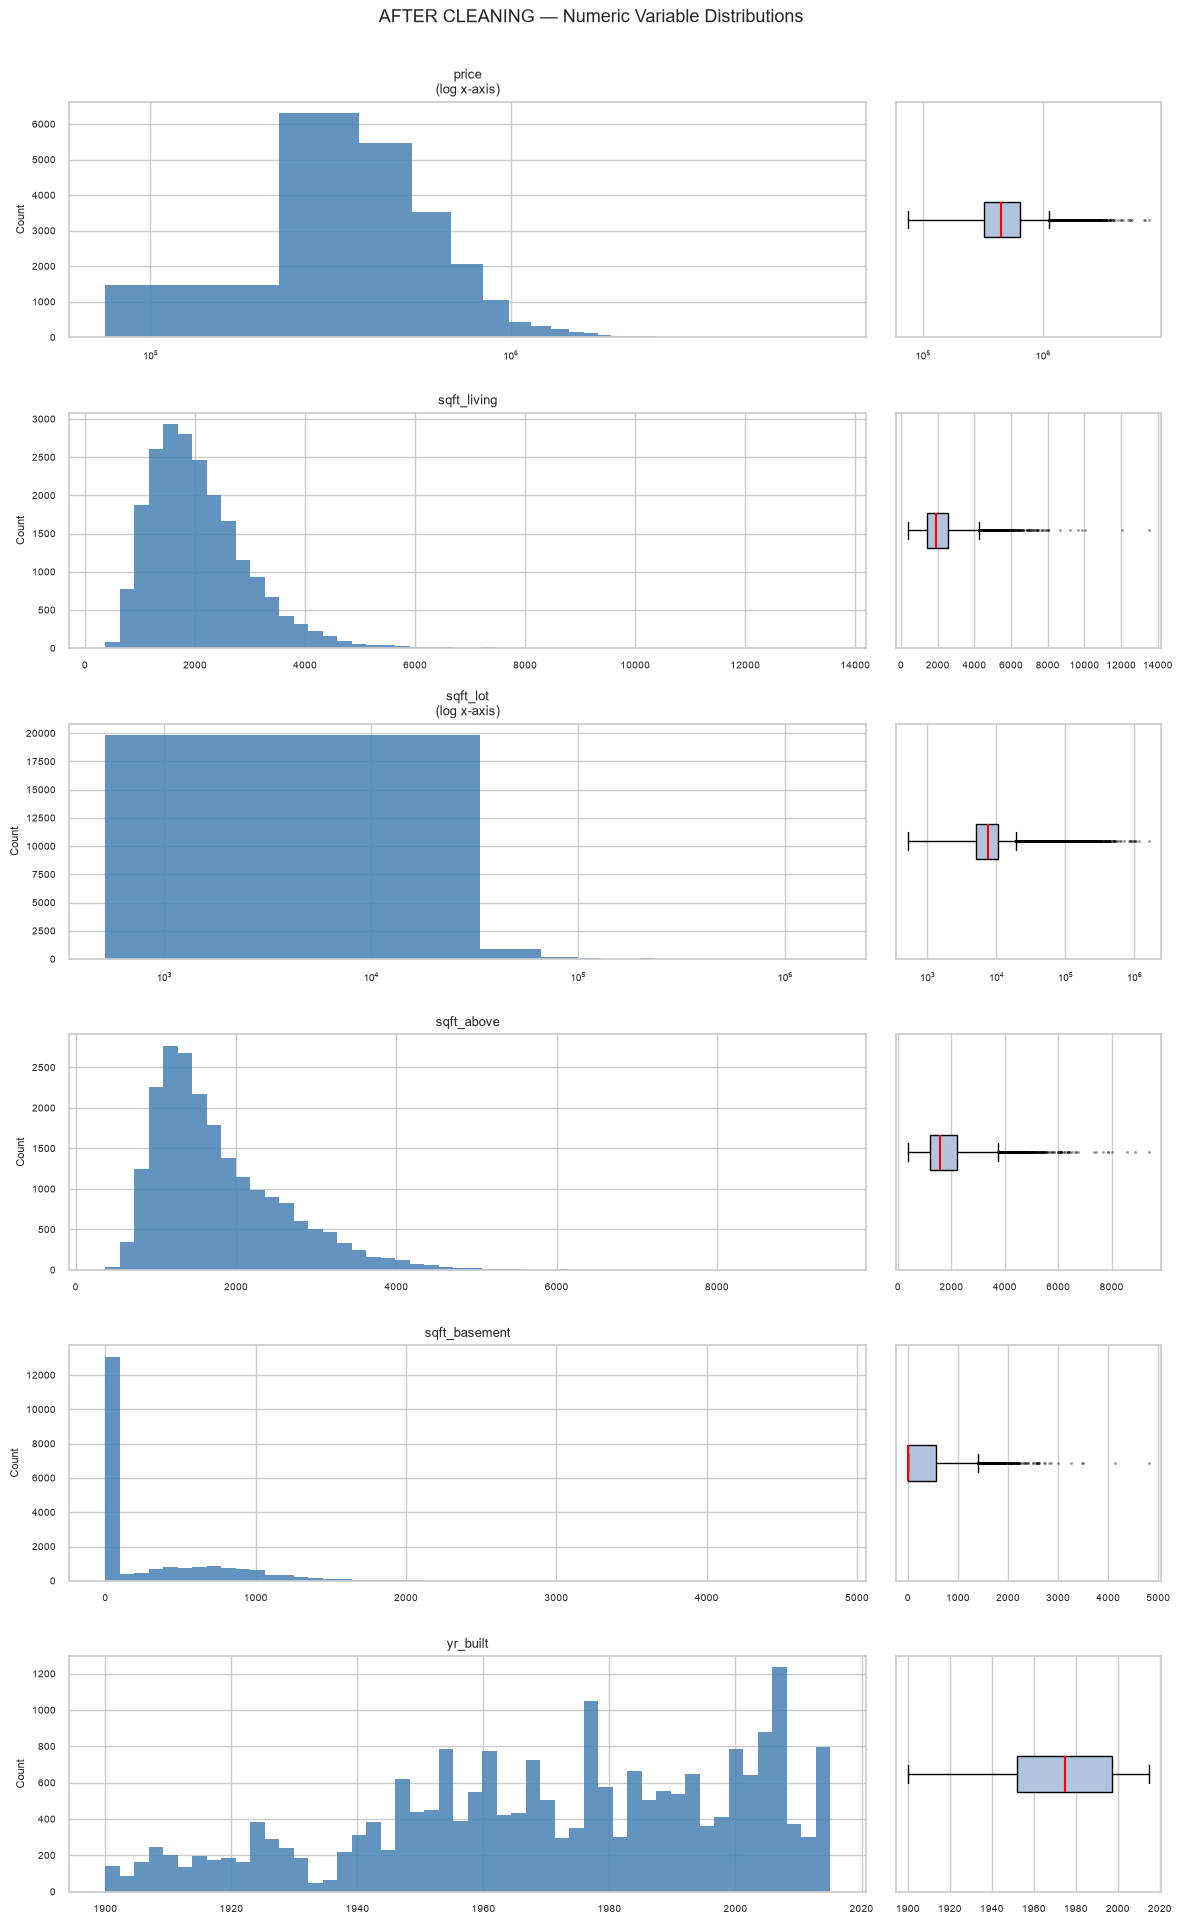

In [31]:
# Numeric distributions AFTER cleaning
n_cols_plot_clean = len(NUMERIC_COLS_CLEAN)
fig, axes = plt.subplots(nrows=n_cols_plot_clean, ncols=2,
                         figsize=(12, 3.2 * n_cols_plot_clean),
                         gridspec_kw={'width_ratios': [3, 1]})

fig.suptitle('AFTER CLEANING — Numeric Variable Distributions', fontsize=13, y=1.002)

for i, col in enumerate(NUMERIC_COLS_CLEAN):
    use_log = col in LOG_SCALE_COLS
    plot_numeric_distribution(df[col], col, use_log=use_log,
                               ax_hist=axes[i, 0], ax_box=axes[i, 1])

plt.tight_layout()
plt.show()

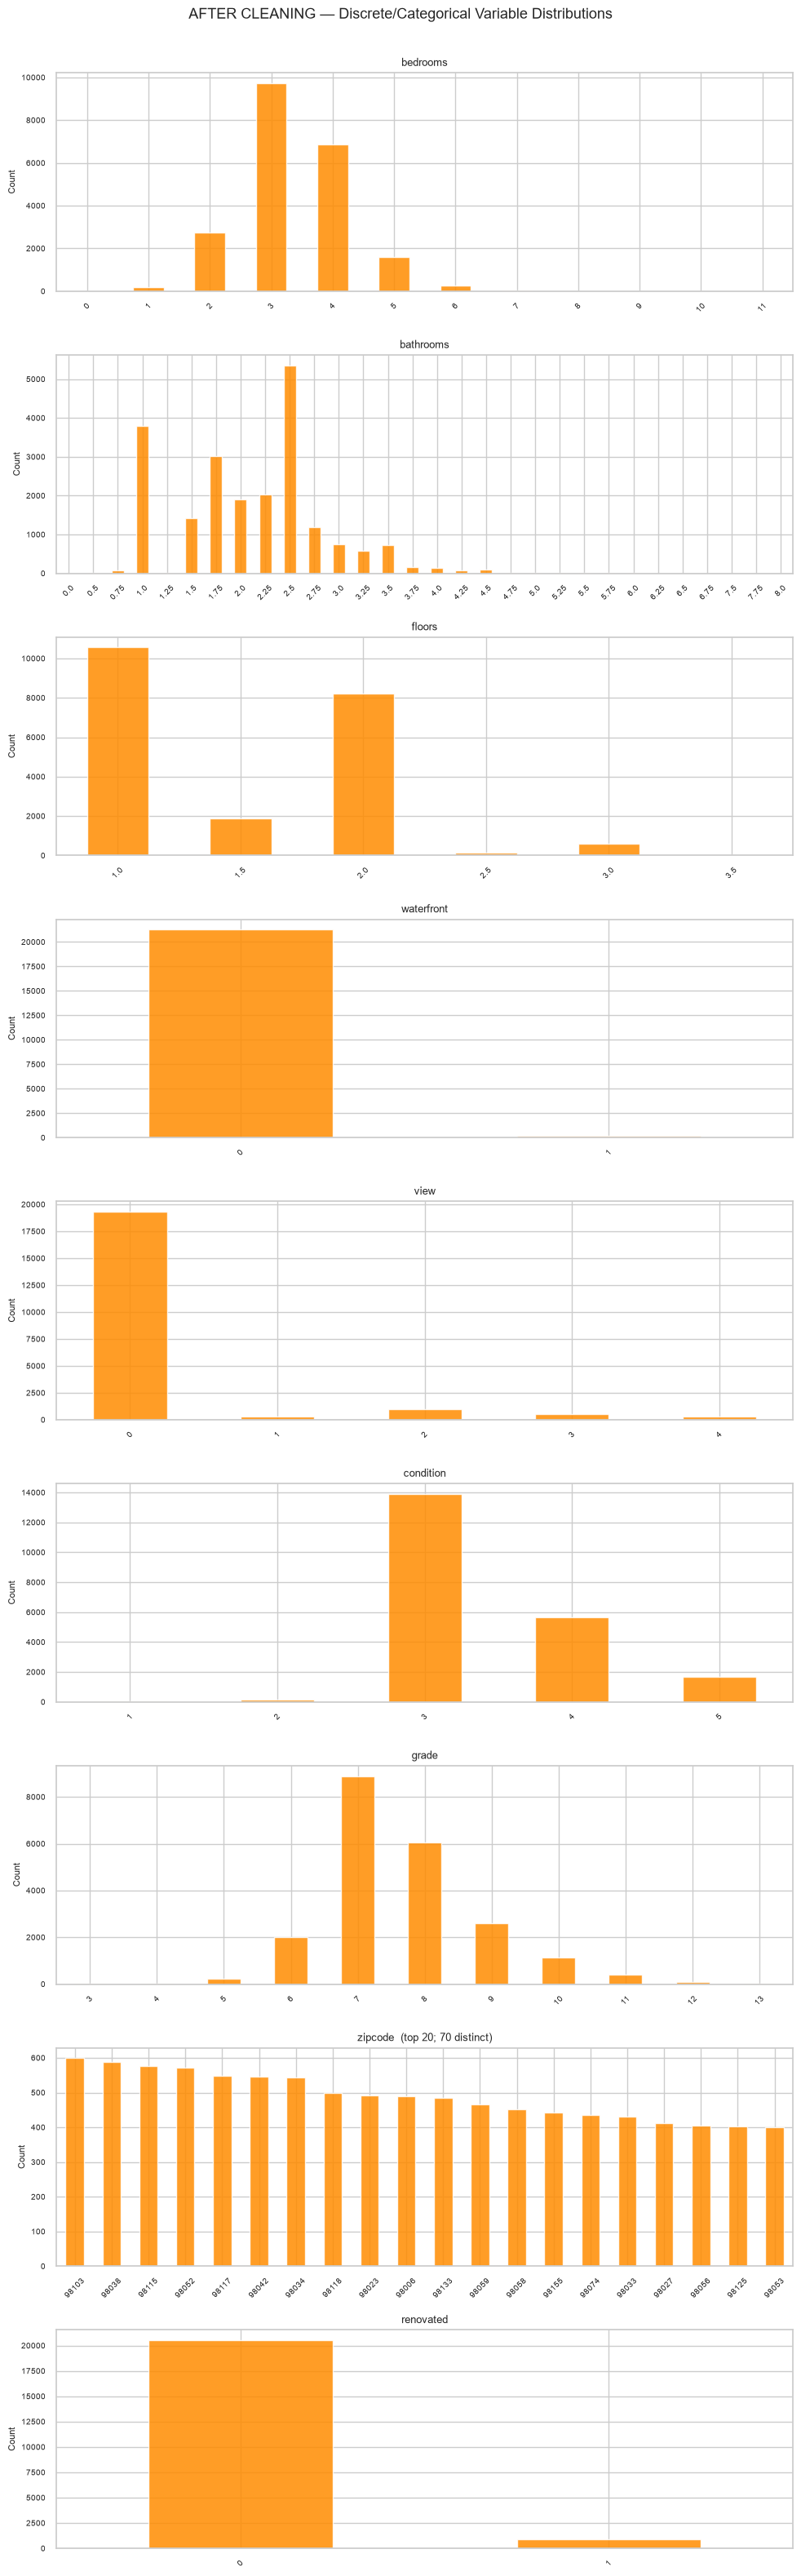

In [32]:
# Discrete distributions AFTER cleaning
n_disc_clean = len(DISCRETE_COLS_CLEAN)
fig, axes = plt.subplots(nrows=n_disc_clean, ncols=1,
                         figsize=(10, 3.5 * n_disc_clean))

fig.suptitle('AFTER CLEANING — Discrete/Categorical Variable Distributions',
             fontsize=13, y=1.002)

for i, col in enumerate(DISCRETE_COLS_CLEAN):
    ax = axes[i]
    vc = df[col].value_counts().sort_index()

    if col == 'zipcode':
        vc_show = df[col].value_counts().head(20)
        vc_show.plot(kind='bar', ax=ax, color='darkorange', alpha=0.85)
        n_distinct = df[col].nunique()
        ax.set_title(f'{col}  (top 20; {n_distinct} distinct)', fontsize=9)
    else:
        vc.plot(kind='bar', ax=ax, color='darkorange', alpha=0.85)
        ax.set_title(f'{col}', fontsize=9)

    ax.set_xlabel('')
    ax.set_ylabel('Count', fontsize=8)
    ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.show()

### Before and after

| What | Before | After |
|---|---|---|
| Rows | 21,613 | 21,428 |
| Columns | 21 | 15 |
| Bedrooms spike at 33 | there | gone |
| `yr_renovated` (mostly 0) | there | replaced by `renovated` (0/1) |
| `zipcode` type | int64 | string |
| `date` | string | dropped in Step 9 |
| Repeated house ids | 177 older sales | removed, latest sale kept |
| `lat`, `long`, `sqft_*15` | there | dropped (not form inputs) |

## Step 11 - Before / after summary

A short table comparing the raw and the clean data, then `describe()` on the final data. I'm looking for anything odd: negative prices, 33 bedrooms, ranges that make no sense.

In [33]:
# Shape comparison
RAW_SHAPE   = (21613, 21)   # recorded in Step 2
clean_shape = df.shape

summary = pd.DataFrame({
    'Metric': ['Rows', 'Columns'],
    'Before cleaning': [f'{RAW_SHAPE[0]:,}', str(RAW_SHAPE[1])],
    'After cleaning':  [f'{clean_shape[0]:,}', str(clean_shape[1])],
    'Change': [
        f'-{RAW_SHAPE[0] - clean_shape[0]:,} rows removed',
        f'-{RAW_SHAPE[1] - clean_shape[1]} columns dropped'
    ]
})

print('=== Before / After Summary ===')
display(summary)

print(f'\nFinal columns: {df.columns.tolist()}')

=== Before / After Summary ===


,Metric,Before cleaning,After cleaning,Change
0,Rows,"21,613","21,428",-185 rows removed
1,Columns,21,15,-6 columns dropped



Final columns: ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'zipcode', 'renovated']


In [34]:
# Descriptive statistics — check that all ranges look reasonable
print('=== describe() of final clean dataset ===')
display(df.describe(include='all').T)

=== describe() of final clean dataset ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,"21,428.00",NaN,NaN,NaN,"541,652.32","367,297.07","75,000.00","324,897.00","450,000.00","645,000.00","7,700,000.00"
bedrooms,"21,428.00",NaN,NaN,NaN,3.37,0.91,0.00,3.00,3.00,4.00,11.00
bathrooms,"21,428.00",NaN,NaN,NaN,2.12,0.77,0.00,1.75,2.25,2.50,8.00
sqft_living,"21,428.00",NaN,NaN,NaN,"2,082.73",918.96,370.00,"1,430.00","1,920.00","2,550.00","13,540.00"
sqft_lot,"21,428.00",NaN,NaN,NaN,"15,137.66","41,545.89",520.00,"5,040.00","7,614.50","10,696.25","1,651,359.00"
floors,"21,428.00",NaN,NaN,NaN,1.50,0.54,1.00,1.00,1.50,2.00,3.50
waterfront,"21,428.00",NaN,NaN,NaN,0.01,0.09,0.00,0.00,0.00,0.00,1.00
view,"21,428.00",NaN,NaN,NaN,0.24,0.77,0.00,0.00,0.00,0.00,4.00
condition,"21,428.00",NaN,NaN,NaN,3.41,0.65,1.00,3.00,3.00,4.00,5.00
grade,"21,428.00",NaN,NaN,NaN,7.66,1.17,3.00,7.00,7.00,8.00,13.00


## Step 12 - Save the clean data

Save to `data/clean/house_clean.csv`, then reload it straight away to check the shape and the types. The important point is that `zipcode` is still a string after the round trip. Without the `dtype` hint, pandas turns it back into an integer when reading.

In [37]:

CLEAN_PATH = '../data/clean/house_clean.csv'

# 1. Ensure zipcode is stored as a string before saving
df['zipcode'] = df['zipcode'].astype('string')

# 2. Save the cleaned dataset
df.to_csv(CLEAN_PATH, index=False)
print(f'Saved: {CLEAN_PATH}')

# 3. Reload the dataset with zipcode forced to string
df_reload = pd.read_csv(CLEAN_PATH, dtype={'zipcode': 'string'})

# 4. Display information
print(f'Reloaded shape : {df_reload.shape}')
print(f'zipcode dtype  : {df_reload["zipcode"].dtype}')
print('\nDtypes after reload:')
print(df_reload.dtypes.to_string())

# 5. Validate the dataset
assert df_reload.shape == df.shape, 'SHAPE MISMATCH after reload!'
assert str(df_reload['zipcode'].dtype) in ('object', 'string'), \
    'zipcode must be string!'

print('\nAll checks passed.')

# 6. Update the cleaning log
cleaning_log.append({
    'step': '12 - Save clean CSV',
    'action': f'Save to {CLEAN_PATH} and verify reload',
    'rows_before': len(df),
    'rows_after': len(df_reload),
    'details': 'zipcode dtype verified as string after reload'
})


Saved: ../data/clean/house_clean.csv
Reloaded shape : (21428, 15)
zipcode dtype  : string

Dtypes after reload:
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
zipcode           string
renovated          int64

All checks passed.


## Step 13 - 30-row sample

A random sample of 30 houses from the clean data, saved in `sample_data/sample_houses.csv`. M5 and M6 can use it to try the CSV upload of the site without loading all 21,000 rows, and I will use it for my own tests in Step 7 of the plan.

It has exactly the same columns as the clean file, with `price`, and no category column (M2 adds that label). The seed is fixed, so the same 30 rows come out every time.

In [38]:
SAMPLE_PATH = '../sample_data/sample_houses.csv'

# 30 random rows, random_state=42 so the sample is always the same
df_sample = df.sample(n=30, random_state=RANDOM_STATE)

df_sample.to_csv(SAMPLE_PATH, index=False)

print(f'Saved: {SAMPLE_PATH}')
print(f'Shape: {df_sample.shape}')
print(f'Columns: {df_sample.columns.tolist()}')
print('\nFirst 5 rows:')
display(df_sample.head())

# Quick checks
assert list(df_sample.columns) == list(df.columns), 'Column mismatch!'
assert 'price' in df_sample.columns, 'price column missing!'
assert 'price_category' not in df_sample.columns, 'Unexpected price_category column!'
print('\nAll checks passed.')

cleaning_log.append({
    'step': '13 - Sample file',
    'action': f'Save 30-row sample to {SAMPLE_PATH}',
    'rows_before': len(df),
    'rows_after': len(df),
    'details': '30 rows sampled with random_state=42; same columns as house_clean.csv'
})

Saved: ../sample_data/sample_houses.csv
Shape: (30, 15)
Columns: ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'zipcode', 'renovated']

First 5 rows:


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,zipcode,renovated
15324,"402,000.00",4,1.75,2430,5481,1.00,0,0,3,8,1430,1000,1953,98108,0
6076,"425,000.00",2,1.00,1160,5038,1.00,0,0,5,7,740,420,1942,98126,0
2534,"699,000.00",4,2.50,3230,40319,2.00,0,0,4,10,3230,0,1987,98027,0
14526,"248,500.00",2,1.00,720,5160,1.00,0,0,3,6,720,0,1949,98106,0
4393,"649,000.00",2,1.00,1280,4840,1.00,0,0,3,7,1200,80,1908,98115,0



All checks passed.


## Step 14 - Cleaning report

Each step above added a line to `cleaning_log`. Here I show it as a table first (next cell), then write it into an Excel file with two sheets: the list of steps, and a final summary of rows and columns before and after.

The point is that anyone in the team, or the person grading the report, can see every change without reading the code. Note that this step needs `openpyxl`.

In [39]:
LOG_PATH = '../report/cleaning_log.md'

log_df = pd.DataFrame(cleaning_log)

print('=== Cleaning Log Table ===')
display(log_df)

=== Cleaning Log Table ===


,step,action,rows_before,rows_after,details
0,3 - Missing values,No missing values found — no action taken,21613,21613,All 21 columns have 0 missing values
1,5a - Fix types,Convert date to datetime64,21613,21613,0 values could not be parsed (NaT)
2,5b - Fix types,Convert zipcode from int64 to string,21613,21613,"Zipcode is a label, not a number. Arithmetic o..."
3,6a - Duplicates,Drop fully duplicate rows,21613,21613,0 fully duplicate rows removed
4,6b - Duplicate IDs,Keep only most recent sale per house id,21613,21436,177 older re-sale rows removed
5,7a - Impossible values,Remove rows with price <= 0 or sqft_living <= 0,21436,21436,0 rows removed
6,7b - Impossible values,Remove rows with bedrooms=0 AND bathrooms=0,21436,21429,7 uninhabitable rows removed
7,7d - Suspicious bedrooms,Remove rows where bedrooms >= 10 AND sqft_livi...,21429,21428,"1 rows removed (e.g., 33-bedroom/1620 sqft house)"
8,7f - Date consistency,"Check yr_built vs sale year, yr_renovated vs y...",21428,21428,12 rows with yr_built > sale_year; 0 rows with...
9,7g - sqft consistency,Report sqft_above + sqft_basement != sqft_livi...,21428,21428,0 rows with sqft mismatch; kept as rounding ar...


In [42]:

import os
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Border, Side, Alignment
from openpyxl.worksheet.table import Table, TableStyleInfo

# ============================================================
# 1. CONFIGURATION
# ============================================================

LOG_PATH = '../reports/M1_data_cleaning_report.xlsx'

RAW_ROWS = 21613
RAW_COLUMNS = 21

# Project color palette
NAVY = '1F3B5C'
BLUE = '2F4F75'
GOLD = 'D4AF5A'
WHITE = 'FFFFFF'
LIGHT = 'F3F6FA'
GRAY = 'D9E1F2'

# Create the output directory if necessary
os.makedirs(os.path.dirname(LOG_PATH) or '.', exist_ok=True)

# ============================================================
# 2. CREATE WORKBOOK
# ============================================================

wb = Workbook()
wb.properties.title = 'M1 - Data Cleaning Report'
wb.properties.subject = 'King County House Sales Dataset'
wb.properties.creator = 'M1_data_cleaning.ipynb'

# ============================================================
# 3. SHEET 1: CLEANING STEPS
# ============================================================

ws = wb.active
ws.title = 'Cleaning Steps'
ws.sheet_view.showGridLines = False

# Main title
ws.merge_cells('A1:E1')
ws['A1'] = 'M1 — DATA CLEANING LOG'
ws['A1'].font = Font(name='Arial', size=18, bold=True, color=WHITE)
ws['A1'].fill = PatternFill('solid', fgColor=NAVY)
ws['A1'].alignment = Alignment(vertical='center')
ws.row_dimensions[1].height = 38

# Dataset information
metadata = [
    ('Dataset', 'King County House Sales (usa_house_data.csv)'),
    ('Notebook', 'notebooks/M1_data_cleaning.ipynb'),
    ('Output', 'data/clean/house_clean.csv'),
    ('Random state', 42),
]

for row_num, (label, value) in enumerate(metadata, start=3):
    ws.cell(row_num, 1, label)
    ws.cell(row_num, 1).font = Font(bold=True, color=NAVY)
    ws.cell(row_num, 1).fill = PatternFill('solid', fgColor=LIGHT)

    ws.merge_cells(
        start_row=row_num, start_column=2,
        end_row=row_num, end_column=5
    )
    ws.cell(row_num, 2, value)
    ws.cell(row_num, 2).alignment = Alignment(vertical='center')

# Cleaning steps table
header_row = 8
headers = [
    'Step',
    'Action',
    'Rows Before',
    'Rows After',
    'Details'
]

for col_num, header in enumerate(headers, start=1):
    cell = ws.cell(header_row, col_num, header)
    cell.font = Font(bold=True, color=WHITE)
    cell.fill = PatternFill('solid', fgColor=BLUE)
    cell.alignment = Alignment(
        horizontal='center',
        vertical='center',
        wrap_text=True
    )

ws.row_dimensions[header_row].height = 28

# Insert cleaning log entries
for row_num, entry in enumerate(cleaning_log, start=header_row + 1):
    values = [
        entry.get('step', ''),
        entry.get('action', ''),
        entry.get('rows_before', ''),
        entry.get('rows_after', ''),
        entry.get('details', '')
    ]

    for col_num, value in enumerate(values, start=1):
        cell = ws.cell(row_num, col_num, value)
        cell.alignment = Alignment(
            vertical='top',
            wrap_text=True
        )
        cell.border = Border(
            bottom=Side(style='thin', color=GRAY)
        )

        if row_num % 2 == 0:
            cell.fill = PatternFill('solid', fgColor=LIGHT)

    # Format row counts
    for col_num in (3, 4):
        ws.cell(row_num, col_num).number_format = '#,##0'

    ws.row_dimensions[row_num].height = 36

last_log_row = header_row + len(cleaning_log)

# Add Excel table with filters and alternating row styles
if cleaning_log:
    table = Table(
        displayName='CleaningStepsTable',
        ref=f'A{header_row}:E{last_log_row}'
    )

    table_style = TableStyleInfo(
        name='TableStyleMedium2',
        showFirstColumn=False,
        showLastColumn=False,
        showRowStripes=True,
        showColumnStripes=False
    )

    table.tableStyleInfo = table_style
    ws.add_table(table)

# Column widths
widths = {
    'A': 26,
    'B': 42,
    'C': 16,
    'D': 16,
    'E': 58
}

for column, width in widths.items():
    ws.column_dimensions[column].width = width

# Navigation and printing settings
ws.freeze_panes = 'A9'
ws.sheet_properties.pageSetUpPr.fitToPage = True
ws.page_setup.fitToWidth = 1
ws.page_setup.fitToHeight = 0
ws.page_setup.orientation = 'landscape'
ws.print_title_rows = '1:8'

# ============================================================
# 4. SHEET 2: FINAL SUMMARY
# ============================================================

summary = wb.create_sheet('Final Summary')
summary.sheet_view.showGridLines = False

summary.merge_cells('A1:C1')
summary['A1'] = 'FINAL DATASET SUMMARY'
summary['A1'].font = Font(
    name='Arial',
    size=18,
    bold=True,
    color=WHITE
)
summary['A1'].fill = PatternFill('solid', fgColor=NAVY)
summary['A1'].alignment = Alignment(vertical='center')
summary.row_dimensions[1].height = 38

summary_data = [
    ('Metric', 'Value', 'Description'),
    ('Raw rows', RAW_ROWS, 'Number of rows in the original dataset'),
    ('Clean rows', len(df), 'Number of rows after cleaning'),
    ('Rows removed', RAW_ROWS - len(df),
     'Difference between raw and clean row counts'),
    ('Raw columns', RAW_COLUMNS,
     'Number of original dataset columns'),
    ('Clean columns', len(df.columns),
     'Number of columns after cleaning'),
    ('New feature', 'renovated',
     'Binary feature derived from yr_renovated'),
    ('Clean dataset',
     'data/clean/house_clean.csv',
     'Main cleaned dataset'),
    ('Sample dataset',
     'sample_data/sample_houses.csv',
     'Sample houses output'),
    ('Notebook',
     'notebooks/M1_data_cleaning.ipynb',
     'Notebook used for data cleaning'),
    ('Random state', 42,
     'Seed used for reproducibility')
]

for row_num, row_data in enumerate(summary_data, start=3):
    for col_num, value in enumerate(row_data, start=1):
        cell = summary.cell(row_num, col_num, value)
        cell.alignment = Alignment(
            vertical='top',
            wrap_text=True
        )

        if row_num == 3:
            cell.font = Font(bold=True, color=WHITE)
            cell.fill = PatternFill('solid', fgColor=BLUE)
            cell.alignment = Alignment(
                horizontal='center',
                vertical='center',
                wrap_text=True
            )
        else:
            cell.border = Border(
                bottom=Side(style='thin', color=GRAY)
            )

            if row_num % 2 == 0:
                cell.fill = PatternFill('solid', fgColor=LIGHT)

            if col_num == 2 and isinstance(value, int):
                cell.number_format = '#,##0'

summary.row_dimensions[3].height = 28

# Summary column widths
summary.column_dimensions['A'].width = 25
summary.column_dimensions['B'].width = 42
summary.column_dimensions['C'].width = 52

summary.freeze_panes = 'A4'
summary.auto_filter.ref = f'A3:C{2 + len(summary_data)}'

# Report footer
footer_row = 4 + len(summary_data) + 1

summary.merge_cells(
    start_row=footer_row,
    start_column=1,
    end_row=footer_row,
    end_column=3
)

footer = summary.cell(
    footer_row,
    1,
    'Report generated by M1_data_cleaning.ipynb'
)
footer.font = Font(italic=True, color=BLUE, size=10)

# ============================================================
# 5. SAVE REPORT
# ============================================================

wb.save(LOG_PATH)

print('=' * 55)
print('DATA CLEANING REPORT GENERATED SUCCESSFULLY')
print('=' * 55)
print(f'File       : {os.path.abspath(LOG_PATH)}')
print(f'Log entries: {len(cleaning_log)}')
print(f'Clean rows : {len(df):,}')
print(f'Clean cols : {len(df.columns)}')
print(f'Rows removed: {RAW_ROWS - len(df):,}')
print('Sheets     : Cleaning Steps, Final Summary')
print('=' * 55)


DATA CLEANING REPORT GENERATED SUCCESSFULLY
File       : c:\Users\ENPEI\Desktop\anti\reports\M1_data_cleaning_report.xlsx
Log entries: 16
Clean rows : 21,428
Clean cols : 15
Rows removed: 185
Sheets     : Cleaning Steps, Final Summary


## Step 15 - Hand-over for the rest of the team

What the others need from me to carry on:
- the final columns and their types, for M2 and M3
- the possible values of each categorical column, for the dropdowns of the form (M6)
- the min and max of the numeric columns, for the limits on the form fields (M6) and the checks in the back end (M5)

In [43]:
print('=' * 70)
print('HAND-OVER DOCUMENT — M1 to M2 / M3 / M4')
print('=' * 70)
print()

# (a) Final column list with dtypes
print('(a) FINAL COLUMNS AND DTYPES')
print('-' * 40)
for col, dtype in df.dtypes.items():
    print(f'  {col:<20s}  {str(dtype)}')
print()

HAND-OVER DOCUMENT — M1 to M2 / M3 / M4

(a) FINAL COLUMNS AND DTYPES
----------------------------------------
  price                 float64
  bedrooms              int64
  bathrooms             float64
  sqft_living           int64
  sqft_lot              int64
  floors                float64
  waterfront            int64
  view                  int64
  condition             int64
  grade                 int64
  sqft_above            int64
  sqft_basement         int64
  yr_built              int64
  zipcode               string
  renovated             int64



In [44]:
# (b) Categorical columns — possible values for web form dropdowns
print('(b) CATEGORICAL COLUMN VALUES (for web form dropdowns)')
print('-' * 60)

CAT_COLS = {
    'bedrooms':  'integer',
    'bathrooms': 'float (0.5 increments)',
    'floors':    'float (0.5 increments)',
    'waterfront': 'binary 0/1',
    'view':      'ordinal 0-4',
    'condition': 'ordinal 1-5',
    'grade':     'ordinal 1-13',
    'renovated': 'binary 0/1',
    'zipcode':   'string',
}

for col, note in CAT_COLS.items():
    vals = sorted(df[col].unique())
    if col == 'zipcode':
        n = len(vals)
        print(f'  {col:<14s} ({note}): {n} distinct values')
        print(f'    First 10: {vals[:10]}')
    else:
        print(f'  {col:<14s} ({note}): {vals}')
print()

(b) CATEGORICAL COLUMN VALUES (for web form dropdowns)
------------------------------------------------------------
  bedrooms       (integer): [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]
  bathrooms      (float (0.5 increments)): [np.float64(0.0), np.float64(0.5), np.float64(0.75), np.float64(1.0), np.float64(1.25), np.float64(1.5), np.float64(1.75), np.float64(2.0), np.float64(2.25), np.float64(2.5), np.float64(2.75), np.float64(3.0), np.float64(3.25), np.float64(3.5), np.float64(3.75), np.float64(4.0), np.float64(4.25), np.float64(4.5), np.float64(4.75), np.float64(5.0), np.float64(5.25), np.float64(5.5), np.float64(5.75), np.float64(6.0), np.float64(6.25), np.float64(6.5), np.float64(6.75), np.float64(7.5), np.float64(7.75), np.float64(8.0)]
  floors         (float (0.5 increments)): [np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), 

In [45]:
# (c) Min / max of numeric columns for input validation on the web form
print('(c) MIN / MAX OF NUMERIC COLUMNS (for form validation)')
print('-' * 60)

NUM_COLS_HANDOVER = [
    'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
    'floors', 'sqft_above', 'sqft_basement', 'yr_built', 'grade',
    'condition', 'view', 'waterfront', 'renovated'
]

print(f'  {"Column":<20s}  {"Min":>15s}  {"Max":>15s}')
print(f'  {"-"*20}  {"-"*15}  {"-"*15}')
for col in NUM_COLS_HANDOVER:
    if col in df.columns:
        mn = df[col].min()
        mx = df[col].max()
        print(f'  {col:<20s}  {mn:>15,.2f}  {mx:>15,.2f}')

print()
print('=' * 70)
print('END OF HAND-OVER DOCUMENT')
print('=' * 70)

(c) MIN / MAX OF NUMERIC COLUMNS (for form validation)
------------------------------------------------------------
  Column                            Min              Max
  --------------------  ---------------  ---------------
  price                       75,000.00     7,700,000.00
  bedrooms                         0.00            11.00
  bathrooms                        0.00             8.00
  sqft_living                    370.00        13,540.00
  sqft_lot                       520.00     1,651,359.00
  floors                           1.00             3.50
  sqft_above                     370.00         9,410.00
  sqft_basement                    0.00         4,820.00
  yr_built                     1,900.00         2,015.00
  grade                            3.00            13.00
  condition                        1.00             5.00
  view                             0.00             4.00
  waterfront                       0.00             1.00
  renovated                  

---
## Summary

| Item | Value |
|---|---|
| Raw data | 21,613 rows x 21 columns |
| Clean data | 21,428 rows x 15 columns |
| Rows removed: older sales of the same house | 177 |
| Rows removed: 0 bedrooms and 0 bathrooms | 7 |
| Rows removed: bedroom typo (33 bedrooms, 1,620 sqft) | 1 |
| Rows removed: price or sqft_living <= 0 | 0 (none found) |
| New column | `renovated` (0/1), made from `yr_renovated` |
| Columns dropped | `id`, `date`, `lat`, `long`, `sqft_living15`, `sqft_lot15`, `yr_renovated` |
| Files produced | `data/clean/house_clean.csv`, `sample_data/sample_houses.csv`, `reports/M1_data_cleaning_report.xlsx` |

**M2:** the clean file is ready. Next is the price category and the decision on outliers.
**M3:** preprocessing, baseline and the schema file, working from M2's labelled data.
**M4:** trains the Decision Tree.
**M5 / M6:** back end and form. Use `sample_houses.csv` and the values from Step 15 (b) and (c).